# Submission 3: Custom CNN from Scratch
**Project:** Pneumonia Detection from Chest X-Ray Images using Deep Learning  
**Roadmap Requirement:** Design and train a custom CNN from scratch (Conv/Pool/BN/FC layers, augmentation, early stopping, and full evaluation metrics)[cite: 6, 8].

In [ ]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, BatchNormalization, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Dataset configuration (reuses the same path setup as previous submissions)
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

DATA_DIR = os.path.join(path, "chest_xray", "chest_xray")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join(path, "chest_xray")

TRAIN_DIR = os.path.join(DATA_DIR, 'train')
VAL_DIR = os.path.join(DATA_DIR, 'val')
TEST_DIR = os.path.join(DATA_DIR, 'test')

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Consistent data augmentation pipeline as mandated
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.1,
    horizontal_flip=True
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary'
)

val_generator = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary'
)

test_generator = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='binary', shuffle=False
)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [ ]:
# Build Custom CNN Architecture from Scratch
custom_cnn = Sequential([
    # Block 1
    Conv2D(32, (3,3), activation='relu', input_shape=(224, 224, 3)),
    BatchNormalization(),
    MaxPooling2D(2,2),

    # Block 2
    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    # Block 3
    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D(2,2),

    # Fully Connected Classification Head
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

custom_cnn.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

custom_cnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,245,825 (84.86 MB)

 Trainable params: 22,245,377 (84.86 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# Training with Early Stopping (monitoring validation loss, minimum 5 epochs ensured)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("Starting Custom CNN training...")
start_train_time = time.time()

history_custom = custom_cnn.fit(
    train_generator,
    validation_data=val_generator,
    epochs=25,  # Sufficient training epochs allowed to trigger early stopping if needed
    callbacks=[early_stop],
    verbose=1
)

custom_train_time = time.time() - start_train_time
print(f"⏱️ Training Time: {custom_train_time:.2f} seconds")

Starting Custom CNN training...
Epoch 1/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 1072s 7s/step - accuracy: 0.8988 - loss: 0.3873 - val_accuracy: 0.5000 - val_loss: 18.1474
Epoch 2/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 1079s 7s/step - accuracy: 0.9327 - loss: 0.1739 - val_accuracy: 0.5000 - val_loss: 17.0499
Epoch 3/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 1065s 7s/step - accuracy: 0.9406 - loss: 0.1649 - val_accuracy: 0.5000 - val_loss: 6.6720
Epoch 4/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 1066s 7s/step - accuracy: 0.9523 - loss: 0.1434 - val_accuracy: 0.5625 - val_loss: 1.9482
Epoch 5/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 1064s 7s/step - accuracy: 0.9534 - loss: 0.1397 - val_accuracy: 0.7500 - val_loss: 0.5606
Epoch 6/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 1107s 7s/step - accuracy: 0.9530 - loss: 0.1244 - val_accuracy: 0.7500 - val_loss: 0.6913
Epoch 7/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 1064s 7s/step - accuracy: 0.9578 - loss: 0.1199 - val_accuracy: 0.6250 - val_loss: 3.4395
Epoch 8/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 1062s 7s/step - 

In [ ]:
# Evaluation on Test Set (Tracking Testing Time & Required Metrics)
test_generator.reset()
start_test_time = time.time()
preds = custom_cnn.predict(test_generator)
custom_test_time = time.time() - start_test_time

y_pred = (preds > 0.5).astype(int).ravel()
y_true = test_generator.classes

# Compute Metrics
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred, zero_division=0)
rec = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

print("=" * 60)
print("CUSTOM CNN TEST METRICS")
print("=" * 60)
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")
print(f"Test Time : {custom_test_time:.2f} seconds")
print("-" * 60)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Normal', 'Pneumonia']))

20/20 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step
CUSTOM CNN TEST METRICS
Accuracy  : 0.8830
Precision : 0.8644
Recall    : 0.9641
F1-Score  : 0.9115
Test Time : 33.35 seconds
------------------------------------------------------------

Classification Report:
              precision    recall  f1-score   support

      Normal       0.93      0.75      0.83       234
   Pneumonia       0.86      0.96      0.91       390

    accuracy                           0.88       624
   macro avg       0.90      0.86      0.87       624
weighted avg       0.89      0.88      0.88       624



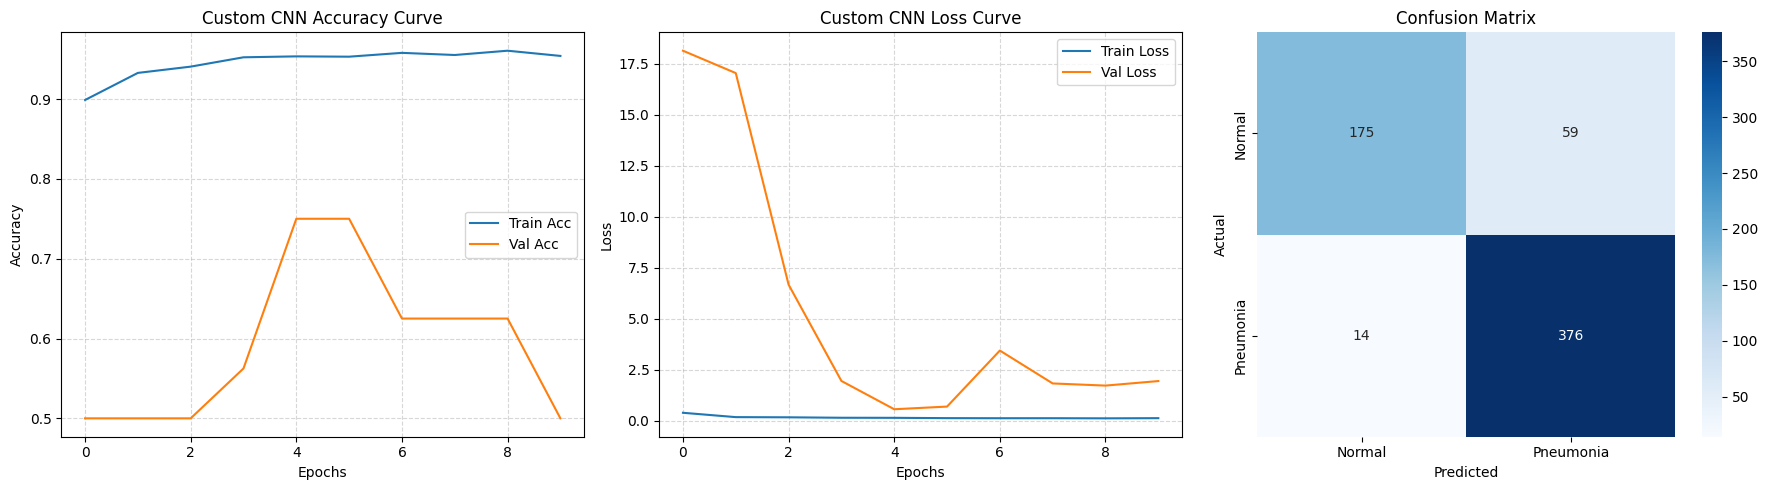

In [ ]:
;.....................................................errrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrrr8hujjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjjnnnnnnnnnnnnnnnnnnnnnnnnnnnnn430----------------------------------------------------------------------------------------------------------------------------------0ppppp# Visualizing Training/Validation Curves and Confusion Matrix (Mandatory Shared Rules)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Accuracy Curve
axes[0].plot(history_custom.history['accuracy'], label='Train Acc', color='#1f77b4')
axes[0].plot(history_custom.history['val_accuracy'], label='Val Acc', color='#ff7f0e')
axes[0].set_title('Custom CNN Accuracy Curve')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Loss Curve
axes[1].plot(history_custom.history['loss'], label='Train Loss', color='#1f77b4')
axes[1].plot(history_custom.history['val_loss'], label='Val Loss', color='#ff7f0e')
axes[1].set_title('Custom CNN Loss Curve')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Normal', 'Pneumonia'], yticklabels=['Normal', 'Pneumonia'])
axes[2].set_title('Confusion Matrix')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()